# K 近邻

### 问题

KNN 是这几个模型里最特殊的:它**没有训练过程**。`fit` 只是把训练集存起来,真正的计算全在 `predict` 里:算出待预测点到所有训练点的距离,取最近的 k 个,谁多就投给谁。

没有参数要学,所以也不用梯度下降。代价是每次预测都要跟整个训练集算距离,数据大的时候很慢。

要决定的只有三件事:距离怎么算、k 取多少、特征尺度要不要统一。

## 1. 数据

还是月牙形数据,600 个点,噪声 0.3。

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=600, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(X_train.shape, X_test.shape)

(420, 2) (180, 2)


## 2. 手算一次预测

拿测试集第一个点,把它到 420 个训练点的距离全算一遍,取最近的 5 个。

In [2]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

q = X_test[0]
d = np.sqrt(((X_train - q) ** 2).sum(axis=1))
idx = np.argsort(d)[:5]

print("距离最近的 5 个点:", idx)
print("它们的标签:", y_train[idx])
print("距离:", d[idx].round(3))
print("投票结果:", np.bincount(y_train[idx].astype(int)).argmax())
print("sklearn 的预测:", knn.predict([q])[0])

距离最近的 5 个点: [285 341 387  93  84]
它们的标签: [0 0 0 0 0]
距离: [0.026 0.043 0.043 0.061 0.063]
投票结果: 0
sklearn 的预测: 0


想投给谁就数谁的票,平票时 sklearn 取索引小的类别。到这里整个模型就讲完了,剩下的都是调参。

顺带一提,`fit` 里真的什么都没算,`knn` 对象里存的就是 `X_train` 和 `y_train` 的副本。

## 3. k 的影响

k 是最关键的参数:k=1 只看最近的一个点,训练集能到 100%,但边界会被噪声带偏;k 太大就把远处不相干的点也算进来,边界变钝,训练集都分不对了。

In [3]:
for k in [1, 3, 5, 9, 15, 25, 50, 100, 200]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k={k:<4} train={m.score(X_train, y_train):.3f} test={m.score(X_test, y_test):.3f}")

k=1    train=1.000 test=0.844
k=3    train=0.960 test=0.872
k=5    train=0.943 test=0.872
k=9    train=0.933 test=0.867
k=15   train=0.919 test=0.878
k=25   train=0.919 test=0.872
k=50   train=0.912 test=0.883
k=100  train=0.907 test=0.861
k=200  train=0.855 test=0.822


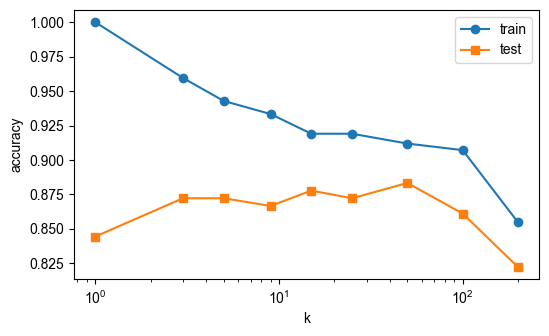

In [4]:
ks = [1, 3, 5, 9, 15, 25, 50, 100, 200]
train_scores, test_scores = [], []

for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(m.score(X_train, y_train))
    test_scores.append(m.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, train_scores, marker="o", label="train")
ax.plot(ks, test_scores, marker="s", label="test")
ax.set_xscale("log")
ax.set_xlabel("k")
ax.set_ylabel("accuracy")
ax.legend()
plt.show()

k=1 训练集 1.0,测试集 0.844,典型的过拟合:每个训练点自己就是一个邻域。k 加到 50,测试集到 0.883 最高,k=200 时训练集掉到 0.855,又欠拟合了。

测试集那条线中间高两头低,所以 k 要挑中间,不能凭感觉。

## 4. 决策边界

k 的大小在图上非常直观。

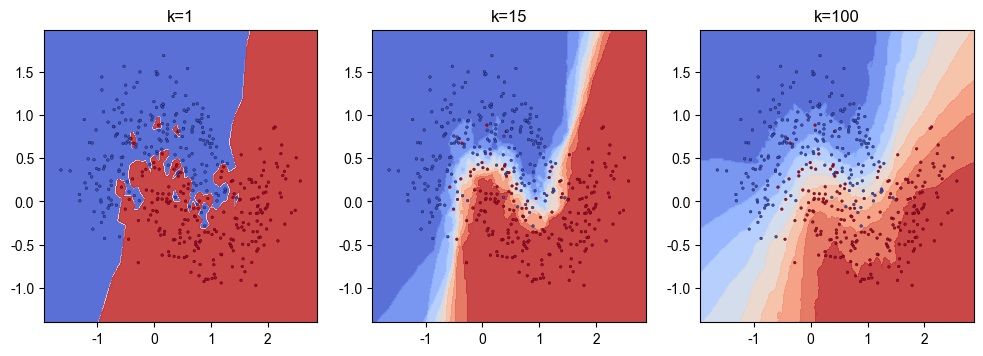

In [5]:
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 250),
                     np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 250))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, k in zip(axs, [1, 15, 100]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    P = m.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, P, levels=10, cmap="coolwarm", alpha=0.9)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=4, cmap="coolwarm",
               edgecolor="black", linewidth=0.2)
    ax.set_title(f"k={k}")

plt.show()

图的颜色是预测概率。k=1 时概率只有 0 和 1 两种,所以是一片红一片蓝,边界碎得很,中间还有被孤立点围出来的小岛。k=15 的边界上出现了一条过渡带,因为 15 个邻居很少全票通过。k=100 的过渡带宽到占了半张图,边界已经钝得看不出月牙的弯。

## 5. 还有哪些参数

除了 k,能调的还有距离权重和距离本身的形式。都试一遍看看值不值得调。

In [6]:
from sklearn.model_selection import cross_val_score

for k in [5, 15, 50]:
    for weights in ["uniform", "distance"]:
        s = cross_val_score(KNeighborsClassifier(k, weights=weights), X, y, cv=5).mean()
        print(f"k={k:<3} weights={weights:<9} CV={s:.4f}")

k=5   weights=uniform   CV=0.9050
k=5   weights=distance  CV=0.9067
k=15  weights=uniform   CV=0.9083
k=15  weights=distance  CV=0.9050
k=50  weights=uniform   CV=0.9033
k=50  weights=distance  CV=0.9117


差别都在 0.01 以内,基本属于波动。`weights="distance"` 是让近的点投票权重大一些,在这份数据里没帮上忙。

k 才是真正要调的,其他参数调半天可能还不如换一个 k。

## 6. 特征缩放

KNN 完全靠距离,哪个特征数值大就听谁的。乳腺癌数据的 30 个特征量纲差得很远。

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

X_c, y_c = load_breast_cancer(return_X_y=True)
X_c_s = StandardScaler().fit_transform(X_c)

print("原始尺度 CV:", round(cross_val_score(KNeighborsClassifier(5), X_c, y_c, cv=5).mean(), 4))
print("标准化后 CV:", round(cross_val_score(KNeighborsClassifier(5), X_c_s, y_c, cv=5).mean(), 4))

for p in [1, 2, 3]:
    s = cross_val_score(KNeighborsClassifier(5, p=p), X_c_s, y_c, cv=5).mean()
    print(f"p={p} CV={s:.4f}")

原始尺度 CV: 0.9279
标准化后 CV: 0.9649
p=1 CV=0.9649


p=2 CV=0.9649


p=3 CV=0.9648


不标准化 0.9279,标准化 0.9649,差了快 4 个点。乳腺癌里面积是几百,平滑度是零点零几,欧氏距离里面积一项就占满了,其他特征等于没参与。

把 p 从 2 改成 1(曼哈顿距离)或者 3,结果几乎一样。距离的形式在低维数据上有讲究,30 维的时候影响就很小了。

## 7. 小结

- KNN 不训练,`fit` 只是存数据,代价全在预测时,每次都要跟整个训练集算距离;
- k 小过拟合,k 大欠拟合,测试集曲线中间高两头低;
- 特征必须标准化,否则距离被大数值特征垄断,这一点和 SVM 一样;
- 距离权重、距离形式这些参数在这份数据上没什么用,别把时间花在这里;
- k 一般取奇数,二分类时能少一点平票;真正的取值还是靠交叉验证。